In [1]:
!pip install xgboost

Defaulting to user installation because normal site-packages is not writeable


XGBOOST CLASSIFIER
AVG_NOISE_LVL ---> Risk_Level

Accuracy : 1.0000

Classification Report

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       873
           1       1.00      1.00      1.00       289
           2       1.00      1.00      1.00      1047

    accuracy                           1.00      2209
   macro avg       1.00      1.00      1.00      2209
weighted avg       1.00      1.00      1.00      2209



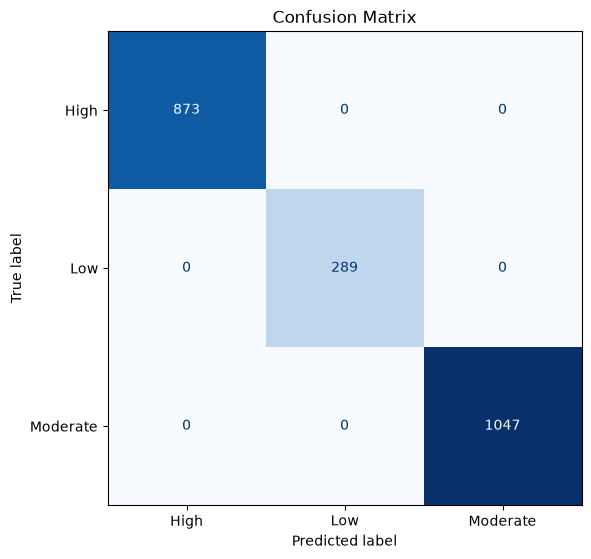


Feature Importance

         Feature  Importance
0  AVG_NOISE_LVL         1.0


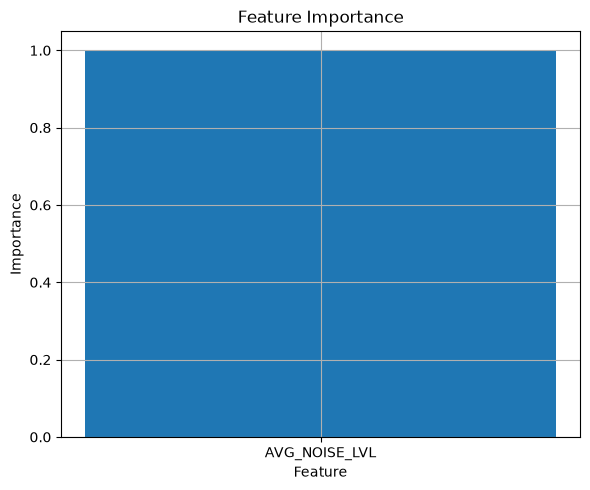

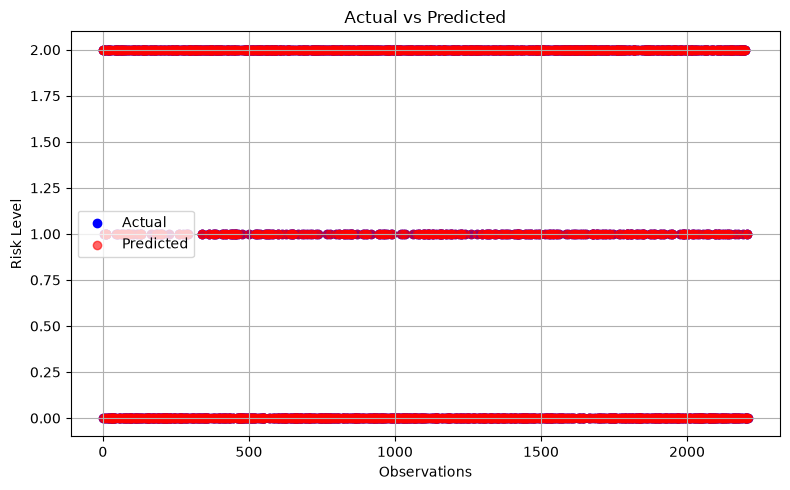


Probability Matrix Shape : (2209, 3)

First Five Probability Rows

[[1.3168847e-04 9.5813069e-05 9.9977249e-01]
 [9.9971157e-01 1.0588392e-04 1.8254353e-04]
 [1.4848236e-04 1.0803187e-04 9.9974352e-01]
 [2.4918010e-04 9.9920112e-01 5.4969103e-04]
 [1.3168847e-04 9.5813069e-05 9.9977249e-01]]

Prediction file saved successfully.

XGBoost Classifier Completed Successfully.


In [3]:
# ==========================================================
# XGBOOST CLASSIFIER
# AVG_NOISE_LVL ---> Risk_Level
# ==========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from xgboost import XGBClassifier

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from sklearn.preprocessing import LabelEncoder

# ==========================================================
# Load Excel File
# ==========================================================

file_path = r"Road_noise_measurements_filled (1).xlsx"
df = pd.read_excel(
    file_path,
    sheet_name="Road_noise_measurements"
)

# ==========================================================
# Keep Required Columns
# ==========================================================

df = df[["AVG_NOISE_LVL","Risk_Level"]]

df = df.dropna()

# ==========================================================
# Encode Risk Level
# ==========================================================

encoder = LabelEncoder()

df["Risk_Level"] = encoder.fit_transform(df["Risk_Level"])

# ==========================================================
# Independent & Dependent Variables
# ==========================================================

X = df[["AVG_NOISE_LVL"]]

Y = df["Risk_Level"]

# ==========================================================
# Train-Test Split
# ==========================================================

X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size=0.30,
    random_state=42,
    stratify=Y
)

# ==========================================================
# Build XGBoost Model
# ==========================================================

model = XGBClassifier(

    objective="multi:softprob",

    num_class=len(np.unique(Y)),

    n_estimators=300,

    learning_rate=0.05,

    max_depth=6,

    subsample=0.8,

    colsample_bytree=0.8,

    random_state=42,

    eval_metric="mlogloss"
)

# ==========================================================
# Train Model
# ==========================================================

model.fit(
    X_train,
    Y_train
)

# ==========================================================
# Prediction
# ==========================================================

Y_pred = model.predict(X_test)

# ==========================================================
# Accuracy
# ==========================================================

accuracy = accuracy_score(
    Y_test,
    Y_pred
)

print("="*70)

print("XGBOOST CLASSIFIER")

print("AVG_NOISE_LVL ---> Risk_Level")

print("="*70)

print(f"\nAccuracy : {accuracy:.4f}")

# ==========================================================
# Classification Report
# ==========================================================

print("\nClassification Report\n")

print(
    classification_report(
        Y_test,
        Y_pred,
        zero_division=0
    )
)

# ==========================================================
# Confusion Matrix
# ==========================================================

cm = confusion_matrix(
    Y_test,
    Y_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=encoder.classes_
)

fig, ax = plt.subplots(figsize=(6,6))

disp.plot(
    ax=ax,
    cmap="Blues",
    colorbar=False
)

plt.title("Confusion Matrix")

plt.tight_layout()

plt.show()

# ==========================================================
# Feature Importance
# ==========================================================

importance = pd.DataFrame({

    "Feature":X.columns,

    "Importance":model.feature_importances_

})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print("\nFeature Importance\n")

print(importance)

# ==========================================================
# Feature Importance Plot
# ==========================================================

plt.figure(figsize=(6,5))

plt.bar(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Feature")

plt.ylabel("Importance")

plt.title("Feature Importance")

plt.grid(True)

plt.tight_layout()

plt.show()

# ==========================================================
# Actual vs Predicted Plot
# ==========================================================

plt.figure(figsize=(8,5))

plt.scatter(
    range(len(Y_test)),
    Y_test,
    color="blue",
    label="Actual"
)

plt.scatter(
    range(len(Y_pred)),
    Y_pred,
    color="red",
    alpha=0.6,
    label="Predicted"
)

plt.xlabel("Observations")

plt.ylabel("Risk Level")

plt.title("Actual vs Predicted")

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

# ==========================================================
# Prediction Probabilities
# ==========================================================

prob = model.predict_proba(X_test)

print("\nProbability Matrix Shape :", prob.shape)

print("\nFirst Five Probability Rows\n")

print(prob[:5])

# ==========================================================
# Save Prediction
# ==========================================================

results = X_test.copy()

results["Actual_Risk_Level"] = encoder.inverse_transform(Y_test)

results["Predicted_Risk_Level"] = encoder.inverse_transform(Y_pred)

results.to_excel(
    "XGBoost_RiskLevel_Predictions.xlsx",
    index=False
)

print("\nPrediction file saved successfully.")

print("\nXGBoost Classifier Completed Successfully.")

XGBOOST REGRESSOR
AVG_NOISE_LVL ---> Duration_hours
R² Score : -0.0145
RMSE     : 4.3706
MAE      : 3.6797

Feature Importance

         Feature  Importance
0  AVG_NOISE_LVL         1.0


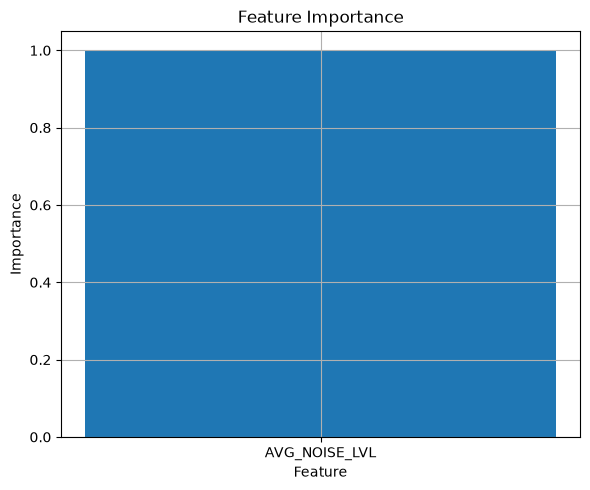

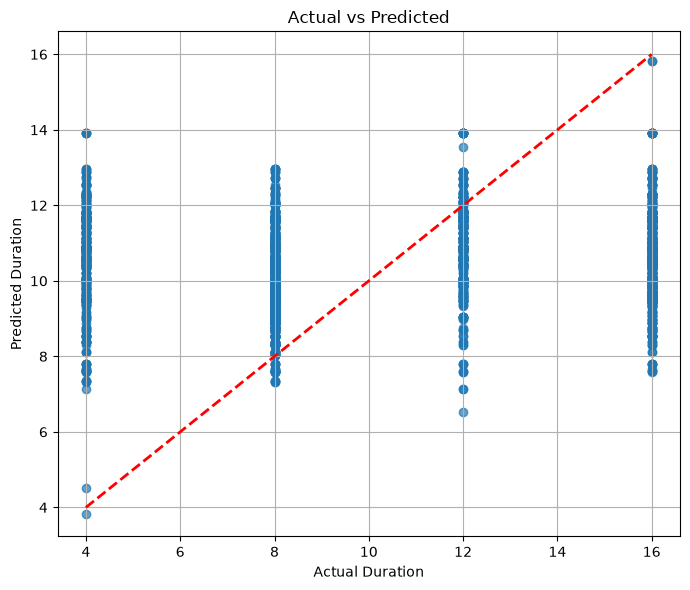

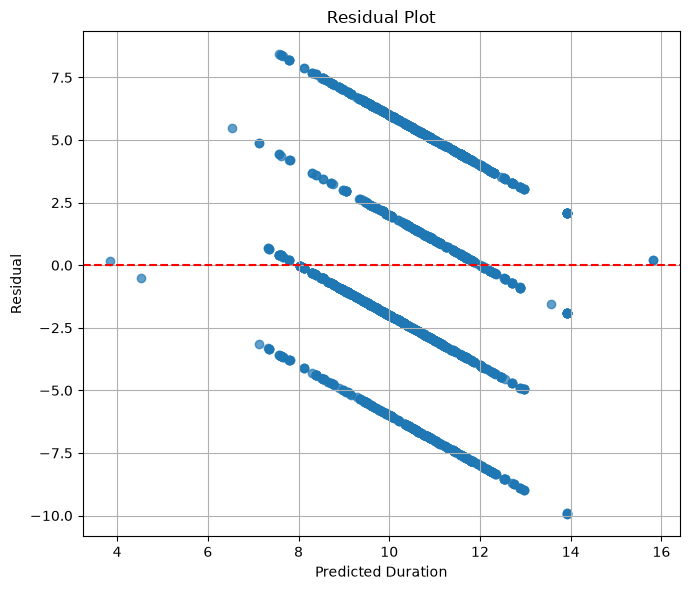

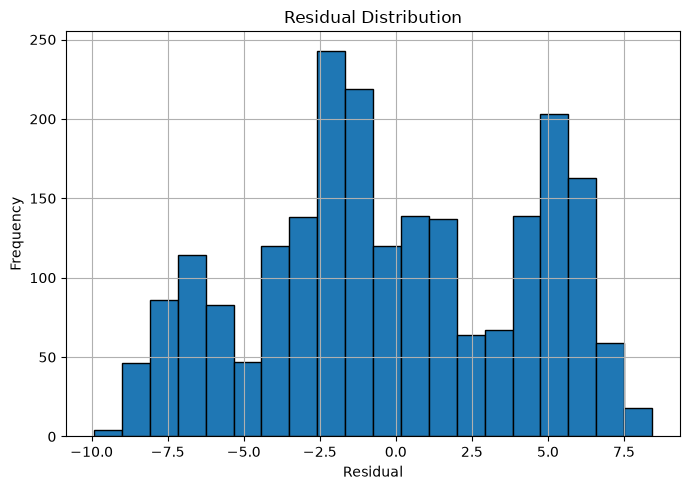


Prediction file saved successfully.

XGBoost Regressor Completed Successfully.


In [4]:
# ==========================================================
# XGBOOST REGRESSOR
# AVG_NOISE_LVL ---> Duration_hours
# ==========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from xgboost import XGBRegressor

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# ==========================================================
# Load Excel File
# ==========================================================


df = pd.read_excel(
    file_path,
    sheet_name="Road_noise_measurements"
)

# ==========================================================
# Keep Required Columns
# ==========================================================

df = df[["AVG_NOISE_LVL","Duration_hours"]]

df = df.dropna()

# ==========================================================
# Independent & Dependent Variables
# ==========================================================

X = df[["AVG_NOISE_LVL"]]

Y = df["Duration_hours"]

# ==========================================================
# Train-Test Split
# ==========================================================

X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size=0.30,
    random_state=42
)

# ==========================================================
# Build XGBoost Regressor
# ==========================================================

model = XGBRegressor(

    n_estimators=300,

    learning_rate=0.05,

    max_depth=6,

    subsample=0.8,

    colsample_bytree=0.8,

    objective="reg:squarederror",

    random_state=42
)

# ==========================================================
# Train Model
# ==========================================================

model.fit(
    X_train,
    Y_train
)

# ==========================================================
# Prediction
# ==========================================================

Y_pred = model.predict(X_test)

# ==========================================================
# Evaluation
# ==========================================================

mse = mean_squared_error(
    Y_test,
    Y_pred
)

rmse = np.sqrt(mse)

mae = mean_absolute_error(
    Y_test,
    Y_pred
)

r2 = r2_score(
    Y_test,
    Y_pred
)

print("="*70)
print("XGBOOST REGRESSOR")
print("AVG_NOISE_LVL ---> Duration_hours")
print("="*70)

print(f"R² Score : {r2:.4f}")
print(f"RMSE     : {rmse:.4f}")
print(f"MAE      : {mae:.4f}")

# ==========================================================
# Feature Importance
# ==========================================================

importance = pd.DataFrame({

    "Feature":X.columns,

    "Importance":model.feature_importances_

})

print("\nFeature Importance\n")

print(importance)

# ==========================================================
# Feature Importance Plot
# ==========================================================

plt.figure(figsize=(6,5))

plt.bar(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Feature")

plt.ylabel("Importance")

plt.title("Feature Importance")

plt.grid(True)

plt.tight_layout()

plt.show()

# ==========================================================
# Actual vs Predicted Plot
# ==========================================================

plt.figure(figsize=(7,6))

plt.scatter(
    Y_test,
    Y_pred,
    alpha=0.7
)

plt.plot(
    [Y_test.min(),Y_test.max()],
    [Y_test.min(),Y_test.max()],
    'r--',
    linewidth=2
)

plt.xlabel("Actual Duration")

plt.ylabel("Predicted Duration")

plt.title("Actual vs Predicted")

plt.grid(True)

plt.tight_layout()

plt.show()

# ==========================================================
# Residual Plot
# ==========================================================

residuals = Y_test - Y_pred

plt.figure(figsize=(7,6))

plt.scatter(
    Y_pred,
    residuals,
    alpha=0.7
)

plt.axhline(
    0,
    color="red",
    linestyle="--"
)

plt.xlabel("Predicted Duration")

plt.ylabel("Residual")

plt.title("Residual Plot")

plt.grid(True)

plt.tight_layout()

plt.show()

# ==========================================================
# Residual Histogram
# ==========================================================

plt.figure(figsize=(7,5))

plt.hist(
    residuals,
    bins=20,
    edgecolor="black"
)

plt.xlabel("Residual")

plt.ylabel("Frequency")

plt.title("Residual Distribution")

plt.grid(True)

plt.tight_layout()

plt.show()

# ==========================================================
# Save Prediction
# ==========================================================

results = X_test.copy()

results["Actual_Duration"] = Y_test.values

results["Predicted_Duration"] = Y_pred

results["Residual"] = residuals

results.to_excel(
    "XGBoost_Duration_Predictions.xlsx",
    index=False
)

print("\nPrediction file saved successfully.")

print("\nXGBoost Regressor Completed Successfully.")

XGBOOST CLASSIFIER
Duration_hours ---> Risk_Level

Accuracy : 0.5491

Classification Report

              precision    recall  f1-score   support

           0       0.55      0.67      0.60       873
           1       0.00      0.00      0.00       289
           2       0.55      0.60      0.58      1047

    accuracy                           0.55      2209
   macro avg       0.37      0.42      0.39      2209
weighted avg       0.48      0.55      0.51      2209



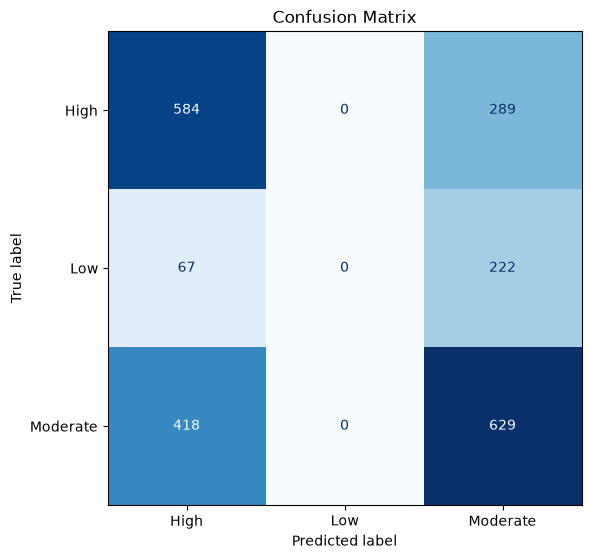


Feature Importance

          Feature  Importance
0  Duration_hours         1.0


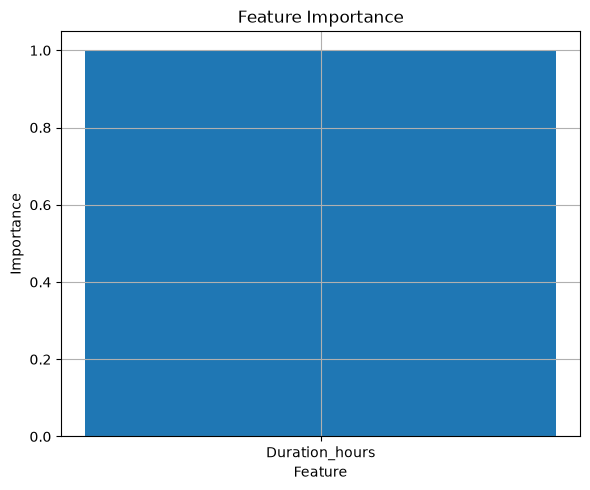

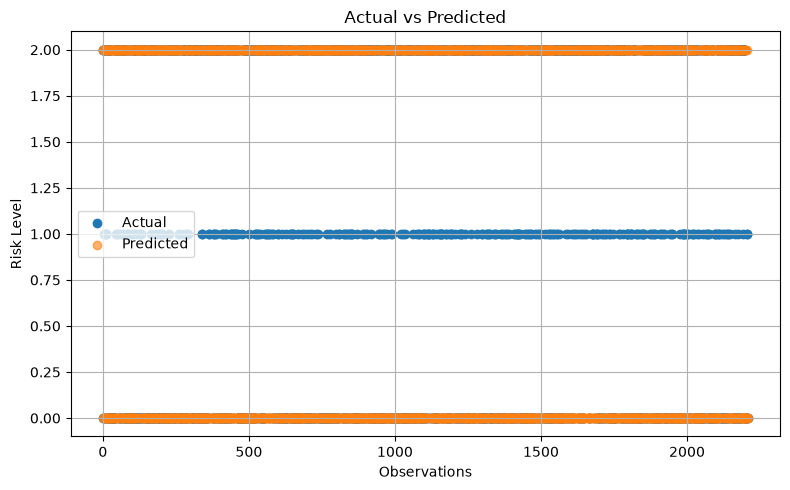


Probability Matrix Shape : (2209, 3)

First Five Probability Rows

[[0.16958767 0.27386537 0.5565469 ]
 [0.45737925 0.10820534 0.43441537]
 [0.16958767 0.27386537 0.5565469 ]
 [0.16958767 0.27386537 0.5565469 ]
 [0.48591262 0.01341265 0.5006747 ]]

Prediction file saved successfully.

XGBoost Classifier Completed Successfully.


In [5]:
# ==========================================================
# XGBOOST CLASSIFIER
# Duration_hours ---> Risk_Level
# ==========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from xgboost import XGBClassifier

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ==========================================================
# Load Excel File
# ==========================================================

file_path = r"Road_noise_measurements_filled (1).xlsx"
df = pd.read_excel(
    file_path,
    sheet_name="Road_noise_measurements"
)

# ==========================================================
# Keep Required Columns
# ==========================================================

df = df[["Duration_hours", "Risk_Level"]]

df = df.dropna()

# ==========================================================
# Encode Risk Level
# ==========================================================

encoder = LabelEncoder()

df["Risk_Level"] = encoder.fit_transform(df["Risk_Level"])

# ==========================================================
# Independent & Dependent Variables
# ==========================================================

X = df[["Duration_hours"]]

Y = df["Risk_Level"]

# ==========================================================
# Train-Test Split
# ==========================================================

X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size=0.30,
    random_state=42,
    stratify=Y
)

# ==========================================================
# Build XGBoost Classifier
# ==========================================================

model = XGBClassifier(

    objective="multi:softprob",

    num_class=len(np.unique(Y)),

    n_estimators=300,

    learning_rate=0.05,

    max_depth=6,

    subsample=0.8,

    colsample_bytree=0.8,

    random_state=42,

    eval_metric="mlogloss"

)

# ==========================================================
# Train Model
# ==========================================================

model.fit(
    X_train,
    Y_train
)

# ==========================================================
# Prediction
# ==========================================================

Y_pred = model.predict(X_test)

# ==========================================================
# Accuracy
# ==========================================================

accuracy = accuracy_score(
    Y_test,
    Y_pred
)

print("="*70)
print("XGBOOST CLASSIFIER")
print("Duration_hours ---> Risk_Level")
print("="*70)

print(f"\nAccuracy : {accuracy:.4f}")

# ==========================================================
# Classification Report
# ==========================================================

print("\nClassification Report\n")

print(
    classification_report(
        Y_test,
        Y_pred,
        zero_division=0
    )
)

# ==========================================================
# Confusion Matrix
# ==========================================================

cm = confusion_matrix(
    Y_test,
    Y_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=encoder.classes_
)

fig, ax = plt.subplots(figsize=(6,6))

disp.plot(
    ax=ax,
    cmap="Blues",
    colorbar=False
)

plt.title("Confusion Matrix")

plt.tight_layout()

plt.show()

# ==========================================================
# Feature Importance
# ==========================================================

importance = pd.DataFrame({

    "Feature":X.columns,

    "Importance":model.feature_importances_

})

print("\nFeature Importance\n")

print(importance)

# ==========================================================
# Feature Importance Plot
# ==========================================================

plt.figure(figsize=(6,5))

plt.bar(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Feature")

plt.ylabel("Importance")

plt.title("Feature Importance")

plt.grid(True)

plt.tight_layout()

plt.show()

# ==========================================================
# Actual vs Predicted Plot
# ==========================================================

plt.figure(figsize=(8,5))

plt.scatter(
    range(len(Y_test)),
    Y_test,
    label="Actual"
)

plt.scatter(
    range(len(Y_pred)),
    Y_pred,
    alpha=0.6,
    label="Predicted"
)

plt.xlabel("Observations")

plt.ylabel("Risk Level")

plt.title("Actual vs Predicted")

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

# ==========================================================
# Prediction Probabilities
# ==========================================================

prob = model.predict_proba(X_test)

print("\nProbability Matrix Shape :", prob.shape)

print("\nFirst Five Probability Rows\n")

print(prob[:5])

# ==========================================================
# Save Predictions
# ==========================================================

results = X_test.copy()

results["Actual_Risk_Level"] = encoder.inverse_transform(Y_test)

results["Predicted_Risk_Level"] = encoder.inverse_transform(Y_pred)

results.to_excel(
    "XGBoost_Duration_vs_RiskLevel.xlsx",
    index=False
)

print("\nPrediction file saved successfully.")

print("\nXGBoost Classifier Completed Successfully.")

XGBOOST REGRESSOR
LONGITUDE ---> Duration_hours
R² Score : 0.0167
RMSE     : 4.3029
MAE      : 3.9105

Feature Importance

     Feature  Importance
0  LONGITUDE         1.0


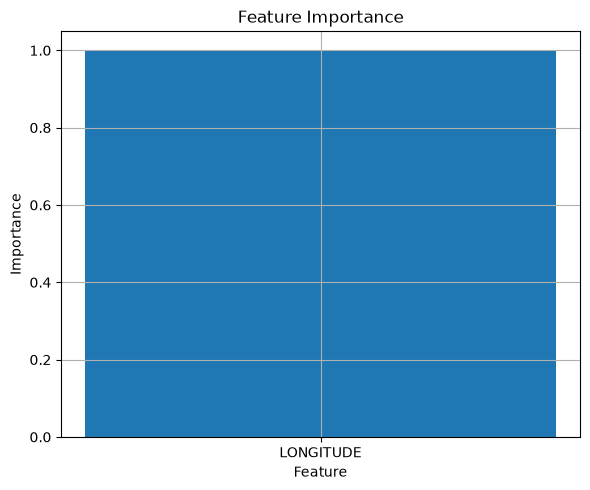

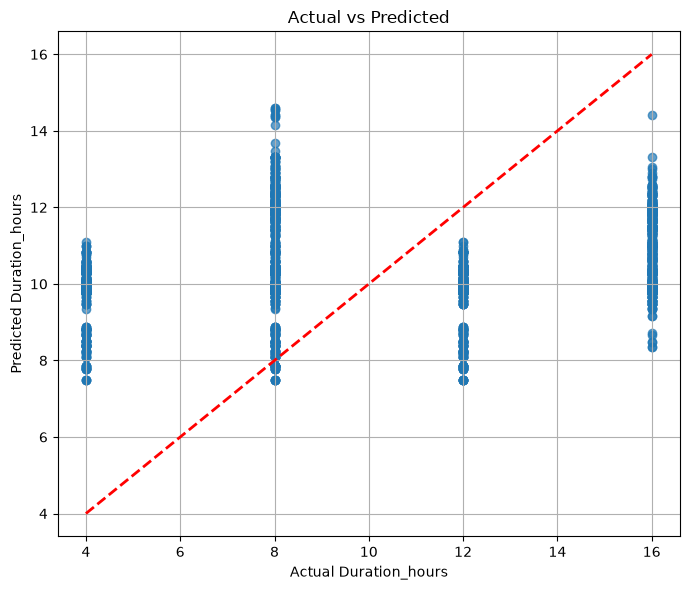

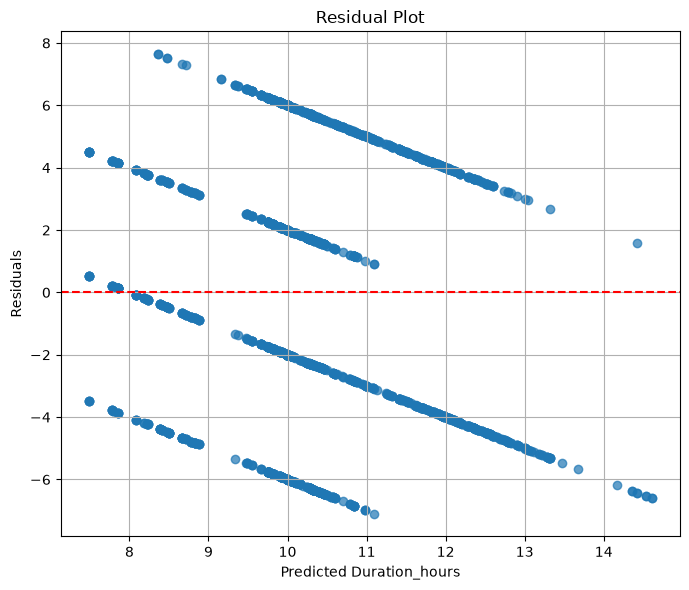

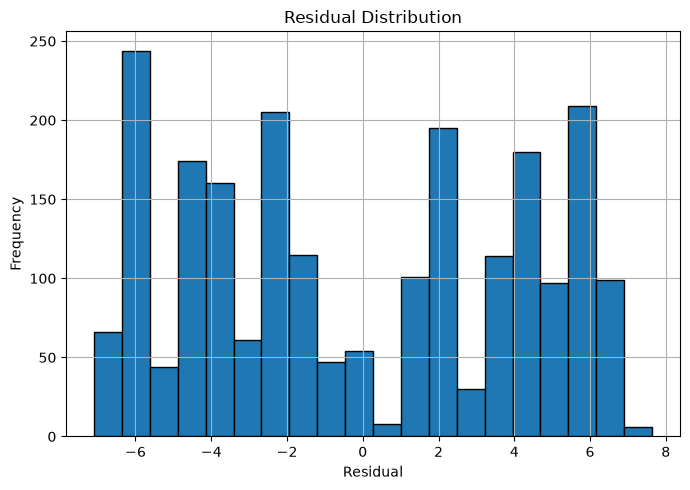


Prediction file saved successfully.

XGBoost Regressor Completed Successfully.


In [7]:
# ==========================================================
# XGBOOST REGRESSOR
# Longitude ---> Duration_hours
# ==========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from xgboost import XGBRegressor

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# ==========================================================
# Load Excel File
# ==========================================================

file_path = r"Road_noise_measurements_filled (1).xlsx"
df = pd.read_excel(
    file_path,
    sheet_name="Road_noise_measurements"
)

# ==========================================================
# Keep Required Columns
# ==========================================================

df = df[["LONGITUDE", "Duration_hours"]]

df = df.dropna()

# ==========================================================
# Independent & Dependent Variables
# ==========================================================

X = df[["LONGITUDE"]]

Y = df["Duration_hours"]

# ==========================================================
# Train-Test Split
# ==========================================================

X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size=0.30,
    random_state=42
)

# ==========================================================
# Build XGBoost Regressor
# ==========================================================

model = XGBRegressor(

    objective="reg:squarederror",

    n_estimators=300,

    learning_rate=0.05,

    max_depth=6,

    subsample=0.8,

    colsample_bytree=0.8,

    random_state=42

)

# ==========================================================
# Train Model
# ==========================================================

model.fit(
    X_train,
    Y_train
)

# ==========================================================
# Prediction
# ==========================================================

Y_pred = model.predict(X_test)

# ==========================================================
# Evaluation
# ==========================================================

mse = mean_squared_error(
    Y_test,
    Y_pred
)

rmse = np.sqrt(mse)

mae = mean_absolute_error(
    Y_test,
    Y_pred
)

r2 = r2_score(
    Y_test,
    Y_pred
)

print("="*70)
print("XGBOOST REGRESSOR")
print("LONGITUDE ---> Duration_hours")
print("="*70)

print(f"R² Score : {r2:.4f}")
print(f"RMSE     : {rmse:.4f}")
print(f"MAE      : {mae:.4f}")

# ==========================================================
# Feature Importance
# ==========================================================

importance = pd.DataFrame({

    "Feature": X.columns,

    "Importance": model.feature_importances_

})

print("\nFeature Importance\n")

print(importance)

# ==========================================================
# Feature Importance Plot
# ==========================================================

plt.figure(figsize=(6,5))

plt.bar(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Feature")

plt.ylabel("Importance")

plt.title("Feature Importance")

plt.grid(True)

plt.tight_layout()

plt.show()

# ==========================================================
# Actual vs Predicted Plot
# ==========================================================

plt.figure(figsize=(7,6))

plt.scatter(
    Y_test,
    Y_pred,
    alpha=0.7
)

plt.plot(
    [Y_test.min(), Y_test.max()],
    [Y_test.min(), Y_test.max()],
    'r--',
    linewidth=2
)

plt.xlabel("Actual Duration_hours")

plt.ylabel("Predicted Duration_hours")

plt.title("Actual vs Predicted")

plt.grid(True)

plt.tight_layout()

plt.show()

# ==========================================================
# Residual Plot
# ==========================================================

residuals = Y_test - Y_pred

plt.figure(figsize=(7,6))

plt.scatter(
    Y_pred,
    residuals,
    alpha=0.7
)

plt.axhline(
    0,
    color="red",
    linestyle="--"
)

plt.xlabel("Predicted Duration_hours")

plt.ylabel("Residuals")

plt.title("Residual Plot")

plt.grid(True)

plt.tight_layout()

plt.show()

# ==========================================================
# Residual Distribution
# ==========================================================

plt.figure(figsize=(7,5))

plt.hist(
    residuals,
    bins=20,
    edgecolor="black"
)

plt.xlabel("Residual")

plt.ylabel("Frequency")

plt.title("Residual Distribution")

plt.grid(True)

plt.tight_layout()

plt.show()

# ==========================================================
# Save Predictions
# ==========================================================

results = X_test.copy()

results["Actual_Duration"] = Y_test.values

results["Predicted_Duration"] = Y_pred

results["Residual"] = residuals

results.to_excel(
    "XGBoost_Longitude_vs_Duration.xlsx",
    index=False
)

print("\nPrediction file saved successfully.")

print("\nXGBoost Regressor Completed Successfully.")